ASSIGNMENT No: 09 
Title: Implement Agglomerative hierarchical clustering algorithm using appropriate dataset. 
Problem Statement: Implement Agglomerative hierarchical clustering algorithm using appropriate 
dataset

Aditya Rade     Roll.No: BEAD23167

Step 1:Import Libraries and load the dataset


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as shc

from sklearn.preprocessing import StandardScaler, normalize
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Load Credit Card dataset
X = pd.read_csv("CC_GENERAL (1).csv")

print("Dataset loaded successfully")
print("Shape:", X.shape)
print(X.head())

Dataset loaded successfully
Shape: (8950, 18)
  CUST_ID      BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0  C10001    40.900749           0.818182      95.40              0.00   
1  C10002  3202.467416           0.909091       0.00              0.00   
2  C10003  2495.148862           1.000000     773.17            773.17   
3  C10004  1666.670542           0.636364    1499.00           1499.00   
4  C10005   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0                    0.000000                          0.

Step 2 — Preprocess the data

In [11]:
# Remove customer ID
X = X.drop("CUST_ID", axis=1)

# Convert all columns to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Handle missing values
X = X.ffill().bfill()

print("Missing values:", X.isnull().sum().sum())
print("Preprocessed data:")
print(X.head())

Missing values: 0
Preprocessed data:
       BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0    40.900749           0.818182      95.40              0.00   
1  3202.467416           0.909091       0.00              0.00   
2  2495.148862           1.000000     773.17            773.17   
3  1666.670542           0.636364    1499.00           1499.00   
4   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0                    0.000000                          0.083333   
1                    0.000000                  

Step 3 — Apply PCA

In [12]:
# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Normalization
X_normalized = normalize(X_scaled)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_normalized)

# Convert PCA result into DataFrame
X_principal = pd.DataFrame(
    X_pca,
    columns=["P1", "P2"]
)

print("PCA completed successfully")
print(X_principal.head())
print("PCA Shape:", X_principal.shape)

PCA completed successfully
         P1        P2
0 -0.489949 -0.679976
1 -0.519099  0.544827
2  0.330633  0.268879
3 -0.481656 -0.097611
4 -0.563512 -0.482506
PCA Shape: (8950, 2)


Step 4 — Create the dendrogram

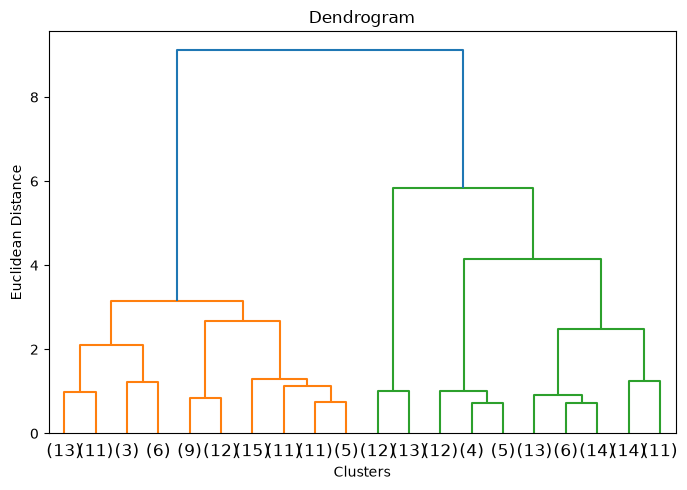

Aditya Rade   BEAD23167


In [15]:
# Select sample for dendrogram
sample_data = X_principal.sample(
    n=min(200, len(X_principal)),
    random_state=42
)

# Calculate linkage
Z = shc.linkage(
    sample_data.to_numpy(),
    method="ward"
)

# Plot dendrogram
plt.figure(figsize=(7, 5))

shc.dendrogram(
    Z,
    truncate_mode="lastp",
    p=20
)

plt.title("Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Euclidean Distance")

plt.tight_layout()
plt.show()
print("Aditya Rade   BEAD23167")

Step 5 — Apply Agglomerative Clustering

In [16]:
# Create models for different numbers of clusters
models = {}

for k in range(2, 7):
    models[k] = AgglomerativeClustering(n_clusters=k)

# Perform clustering with 2 clusters
labels = models[2].fit_predict(X_principal)

print("Agglomerative clustering completed")
print("Number of clusters: 2")
print("Cluster labels:")
print(labels)

Agglomerative clustering completed
Number of clusters: 2
Cluster labels:
[0 0 1 ... 1 0 0]


Step 6 — Visualize the clusters

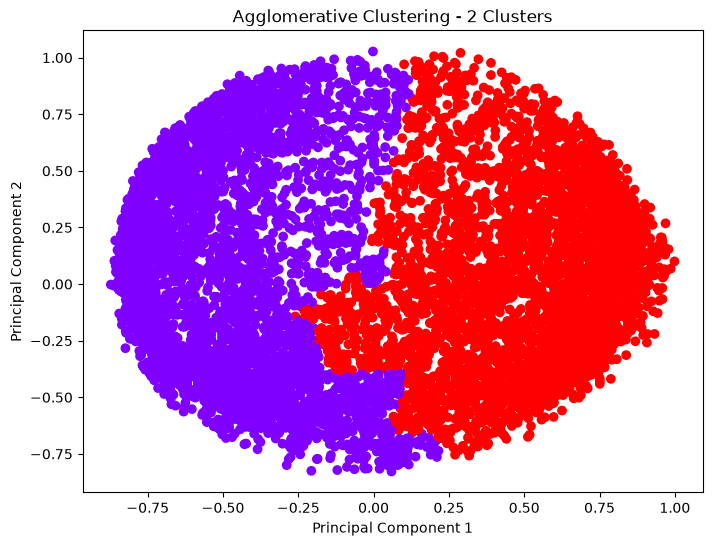

Aditya Rade   BEAD23167


In [17]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_principal["P1"],
    X_principal["P2"],
    c=labels,
    cmap="rainbow"
)

plt.title("Agglomerative Clustering - 2 Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()
print("Aditya Rade   BEAD23167")

Step 7 — Calculate Silhouette Scores

In [18]:
k_values = [2, 3, 4, 5, 6]
silhouette_scores = []

for k in k_values:

    model = AgglomerativeClustering(n_clusters=k)

    labels = model.fit_predict(X_principal)

    score = silhouette_score(
        X_principal,
        labels
    )

    silhouette_scores.append(score)

# Display scores
print("Silhouette Scores:")

for k, score in zip(k_values, silhouette_scores):
    print(f"{k} Clusters: {score:.4f}")

Silhouette Scores:
2 Clusters: 0.4324
3 Clusters: 0.4278
4 Clusters: 0.3747
5 Clusters: 0.3551
6 Clusters: 0.3169


Step 8 — Find the optimal number of clusters

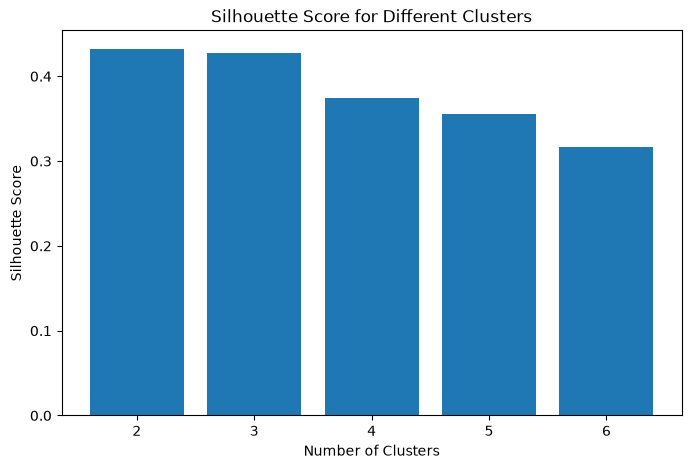

Optimal Number of Clusters: 2
Aditya Rade  BEAD23167


In [19]:
plt.figure(figsize=(8, 5))

plt.bar(
    k_values,
    silhouette_scores
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different Clusters")

plt.show()

# Find best cluster count
best_k = k_values[np.argmax(silhouette_scores)]

print("Optimal Number of Clusters:", best_k)
print("Aditya Rade  BEAD23167")